In [ ]:
import pandas as pd
from itertools import combinations
from google.colab import drive, files

drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/results-2024.csv', low_memory=False)

data = df.dropna(subset=['PlatformHaveWorkedWith']).copy()
data['n_platforms'] = data['PlatformHaveWorkedWith'].str.split(';').str.len()
data = data[data['n_platforms'] <= 19]

# NEW: clean names + keep cloud service providers only
short = {'Amazon Web Services (AWS)': 'AWS', 'Linode, now Akamai': 'Linode (Akamai)',
         'Oracle Cloud Infrastructure (OCI)': 'Oracle Cloud (OCI)', 'IBM Cloud Or Watson': 'IBM Cloud',
         'Digital Ocean': 'DigitalOcean'}
EXCLUDE = ['OpenStack', 'OpenShift', 'VMware', 'Colocation', 'Managed Hosting']
data['platforms'] = data['PlatformHaveWorkedWith'].str.split(';').apply(
    lambda xs: sorted({short.get(x.strip(), x.strip()) for x in xs} - set(EXCLUDE)))
print('Selected only excluded options:', (data['platforms'].str.len() == 0).sum())
data = data[data['platforms'].str.len() > 0]

B = data['platforms'].str.join('|').str.get_dummies()
print('Respondents x platforms:', B.shape)

C = B.T.dot(B)
co = pd.DataFrame([(a, b, C.loc[a, b]) for a, b in combinations(B.columns, 2)],
                  columns=['Platform 1', 'Platform 2', 'Co-use frequency'])
co = co.sort_values('Co-use frequency', ascending=False)
print('Pairs:', len(co))

co.to_csv('cloud_platform_co_use_2024.csv', index=False)
files.download('cloud_platform_co_use_2024.csv')

Mounted at /content/drive
Selected only excluded options: 1029
Respondents x platforms: (41293, 22)
Pairs: 231


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import networkx as nx

G_full = nx.Graph()
for a, b, w in co[['Platform 1', 'Platform 2', 'Co-use frequency']].itertuples(index=False):
    G_full.add_edge(a, b, weight=int(w))

print('Nodes  :', G_full.number_of_nodes())
print('Edges  :', G_full.number_of_edges())
print('Density:', round(nx.density(G_full), 3))
print(co['Co-use frequency'].describe())

Nodes  : 22
Edges  : 231
Density: 1.0
count     231.000000
mean      475.822511
std       837.323987
min         8.000000
25%        60.000000
50%       183.000000
75%       480.000000
max      6445.000000
Name: Co-use frequency, dtype: float64


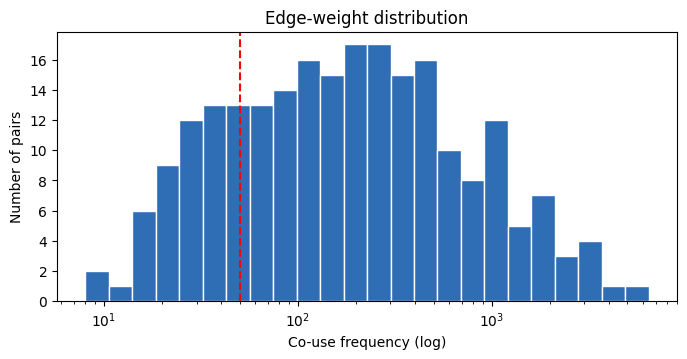

Edges after filtering: 183
Density              : 0.792
Still connected?     : True
Co-use kept (%)      : 98.7


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

w = co['Co-use frequency']
plt.figure(figsize=(8, 3.5))
plt.hist(w, bins=np.logspace(np.log10(w.min()), np.log10(w.max()), 25), color='#2f6db5', edgecolor='white')
plt.axvline(50, color='red', ls='--')
plt.xscale('log')
plt.xlabel('Co-use frequency (log)'); plt.ylabel('Number of pairs')
plt.title('Edge-weight distribution'); plt.show()

THRESHOLD = 50
G = nx.Graph()
G.add_nodes_from(G_full.nodes())
for a, b, d in G_full.edges(data=True):
    if d['weight'] >= THRESHOLD:
        G.add_edge(a, b, weight=d['weight'])

print('Edges after filtering:', G.number_of_edges())
print('Density              :', round(nx.density(G), 3))
print('Still connected?     :', nx.is_connected(G))
print('Co-use kept (%)      :', round(w[w >= THRESHOLD].sum() / w.sum() * 100, 1))

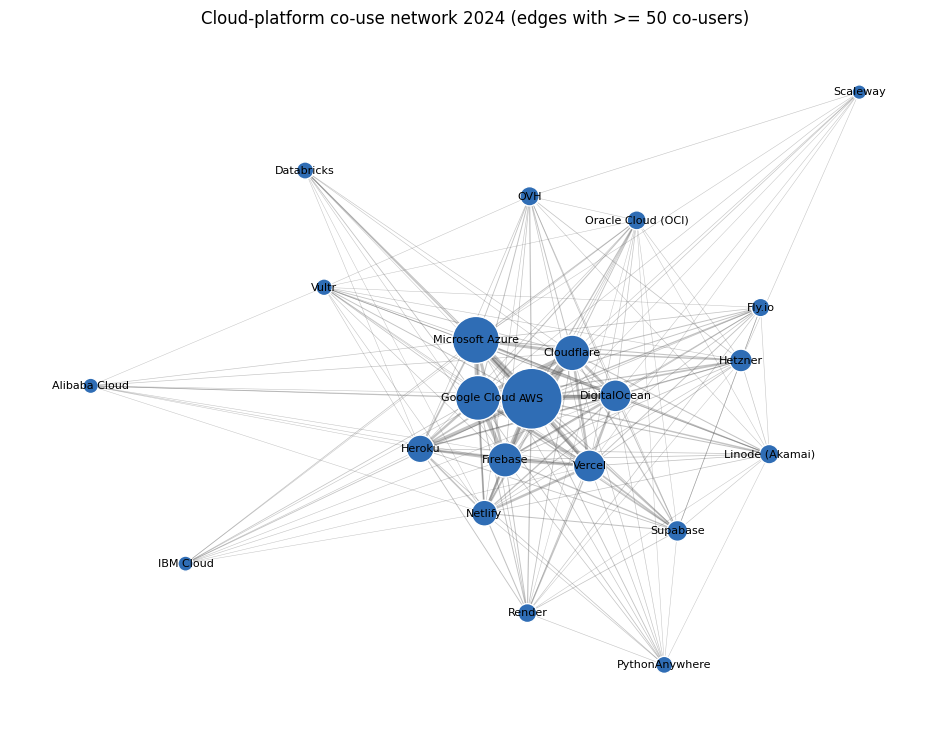

In [ ]:
users = B.sum()

pos = nx.spring_layout(G, weight='weight', seed=7, k=0.9)
ew = np.array([G[u][v]['weight'] for u, v in G.edges()])

plt.figure(figsize=(12, 9))
nx.draw_networkx_edges(G, pos, width=0.3 + 6 * ew / ew.max(), alpha=0.35, edge_color='#555')
nx.draw_networkx_nodes(G, pos, node_size=[80 + users[n] / 12 for n in G.nodes()],
                       node_color='#2f6db5', edgecolors='white')
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title('Cloud-platform co-use network 2024 (edges with >= 50 co-users)')
plt.axis('off')
plt.show()

In [ ]:
import pandas as pd

def summary(H):
    return {
        'Nodes': H.number_of_nodes(),
        'Edges': H.number_of_edges(),
        'Density': round(nx.density(H), 3),
        'Connected components': nx.number_connected_components(H),
        'Average degree': round(np.mean([d for _, d in H.degree()]), 2),
        'Average clustering': round(nx.average_clustering(H), 3),
        'Diameter': nx.diameter(H),
        'Average shortest path': round(nx.average_shortest_path_length(H), 3),
    }

net = pd.DataFrame({'Full network': summary(G_full),
                    'Filtered (>= 50)': summary(G)})
print(net)
print('Assortativity (filtered):', round(nx.degree_assortativity_coefficient(G), 3))

                       Full network  Filtered (>= 50)
Nodes                          22.0            22.000
Edges                         231.0           183.000
Density                         1.0             0.792
Connected components            1.0             1.000
Average degree                 21.0            16.640
Average clustering              1.0             0.889
Diameter                        1.0             2.000
Average shortest path           1.0             1.208
Assortativity (filtered): -0.355


In [ ]:
cent = pd.DataFrame({
    'Users': users,
    'Degree': dict(G.degree()),
    'Strength': dict(G_full.degree(weight='weight')),
    'Closeness': nx.closeness_centrality(G),
    'Betweenness': nx.betweenness_centrality(G),
    'Eigenvector': nx.eigenvector_centrality(G_full, weight='weight', max_iter=1000),
}).round(4).sort_values('Strength', ascending=False)

cent.to_csv('centrality.csv')
cent.head(10)

,Users,Degree,Strength,Closeness,Betweenness,Eigenvector
AWS,22148,21,36362,1.0000,0.0242,0.5203
Google Cloud,11562,21,26504,1.0000,0.0242,0.4290
Microsoft Azure,12808,21,20475,1.0000,0.0242,0.3564
Cloudflare,6932,21,20258,1.0000,0.0242,0.3211
Firebase,6401,21,17007,1.0000,0.0242,0.2802
Vercel,5450,21,16509,1.0000,0.0242,0.2500
DigitalOcean,5366,21,15756,1.0000,0.0242,0.2562
Heroku,3756,20,12100,0.9545,0.0171,0.1963
Netlify,3194,20,10744,0.9545,0.0171,0.1641
Supabase,1726,17,6377,0.8400,0.0030,0.0964


In [ ]:
N = len(B)

co['Lift'] = (co['Co-use frequency'] * N /
              (co['Platform 1'].map(users) * co['Platform 2'].map(users))).round(3)

for a, b, wt, lf in co[['Platform 1', 'Platform 2', 'Co-use frequency', 'Lift']].itertuples(index=False):
    if G.has_edge(a, b):
        G[a][b]['lift'] = lf

kept = co[co['Co-use frequency'] >= THRESHOLD]

print('1) Top 10 pairs by co-use frequency')
display(co.sort_values('Co-use frequency', ascending=False).head(10))
print('2) Top 10 pairs by lift (pairs with >= 50 co-users)')
display(kept.sort_values('Lift', ascending=False).head(10))
print('3) Big pairs used together LESS than chance')
display(co[co['Co-use frequency'] >= 1000].sort_values('Lift').head(6))

co.to_csv('co_use_with_lift.csv', index=False)

1) Top 10 pairs by co-use frequency


,Platform 1,Platform 2,Co-use frequency,Lift
6,AWS,Google Cloud,6445,1.039
11,AWS,Microsoft Azure,5593,0.814
1,AWS,Cloudflare,4116,1.107
130,Google Cloud,Microsoft Azure,3394,0.946
3,AWS,DigitalOcean,3244,1.127
4,AWS,Firebase,3069,0.894
96,Firebase,Google Cloud,2922,1.630
19,AWS,Vercel,2743,0.938
45,Cloudflare,Google Cloud,2662,1.371
7,AWS,Heroku,2300,1.142


2) Top 10 pairs by lift (pairs with >= 50 co-users)


,Platform 1,Platform 2,Co-use frequency,Lift
206,OVH,Scaleway,110,9.395
185,Linode (Akamai),Vultr,164,6.421
40,Alibaba Cloud,Vultr,52,5.554
198,Netlify,Render,491,5.026
121,Fly.io,Render,168,4.785
161,Hetzner,Scaleway,88,4.516
228,Supabase,Vercel,1025,4.499
216,PythonAnywhere,Render,117,4.495
222,Render,Supabase,233,4.414
169,IBM Cloud,Oracle Cloud (OCI),62,4.281


3) Big pairs used together LESS than chance


,Platform 1,Platform 2,Co-use frequency,Lift
193,Microsoft Azure,Vercel,1121,0.663
101,Firebase,Microsoft Azure,1520,0.766
11,AWS,Microsoft Azure,5593,0.814
8,AWS,Hetzner,1005,0.829
85,DigitalOcean,Microsoft Azure,1393,0.837
4,AWS,Firebase,3069,0.894


weight: 2 communities, Q = 0.041, same result in 100/100 runs
lift: 3 communities, Q = 0.148, same result in 100/100 runs
Community 1: ['AWS', 'Microsoft Azure', 'Google Cloud', 'Oracle Cloud (OCI)', 'Databricks', 'IBM Cloud']
Community 2: ['Firebase', 'Vercel', 'Heroku', 'Netlify', 'Supabase', 'Render', 'Fly.io', 'PythonAnywhere']
Community 3: ['Cloudflare', 'DigitalOcean', 'Hetzner', 'Linode (Akamai)', 'OVH', 'Vultr', 'Alibaba Cloud', 'Scaleway']
Greedy modularity gives the same communities? True


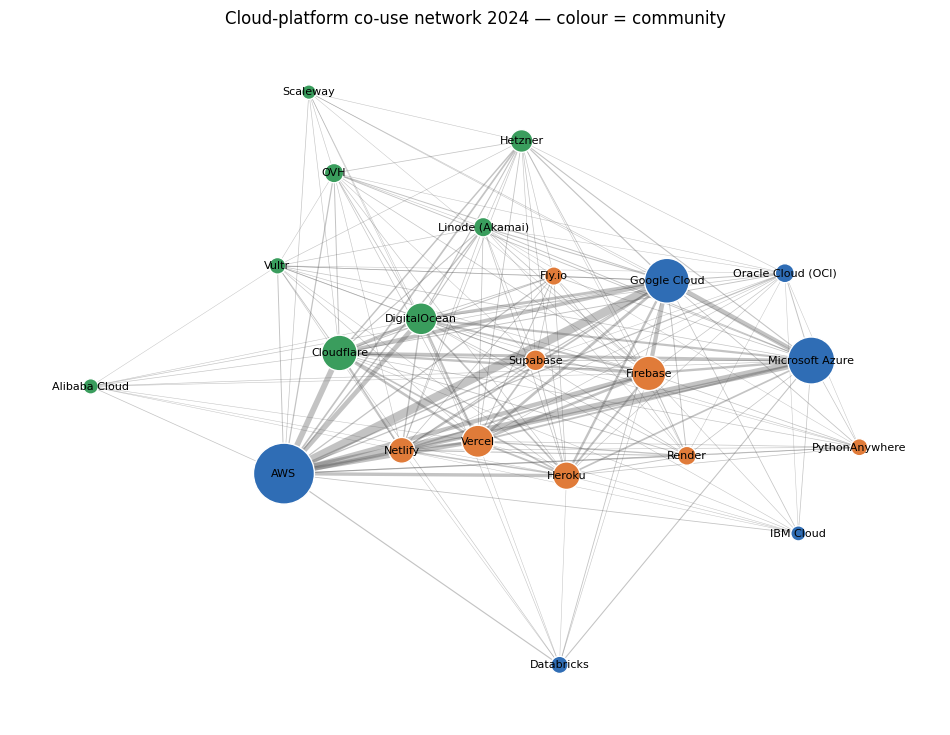

In [ ]:
from collections import Counter

def key(cs):
    return tuple(sorted(tuple(sorted(c)) for c in cs))

def louvain_100(H, weight):
    runs = Counter(key(nx.community.louvain_communities(H, weight=weight, seed=s)) for s in range(100))
    best = max(runs, key=runs.get)
    return [set(c) for c in best], runs[best]

for wk in ['weight', 'lift']:
    cs, n_best = louvain_100(G, wk)
    print(f'{wk}: {len(cs)} communities, Q = {nx.community.modularity(G, cs, weight=wk):.3f}, '
          f'same result in {n_best}/100 runs')

comm_lift, _ = louvain_100(G, 'lift')
comm_lift = sorted(comm_lift, key=lambda c: -users[list(c)].sum())
label = {p: i for i, c in enumerate(comm_lift) for p in c}
for i, c in enumerate(comm_lift, 1):
    print(f'Community {i}:', sorted(c, key=lambda p: -users[p]))

gm = nx.community.greedy_modularity_communities(G, weight='lift')
print('Greedy modularity gives the same communities?', key(gm) == key(comm_lift))

PAL = ['#2f6db5', '#e07b39', '#3a9d5d', '#9b59b6']
pos = nx.spring_layout(G, weight='lift', seed=7, k=0.9)
ew = np.array([G[u][v]['weight'] for u, v in G.edges()])
plt.figure(figsize=(12, 9))
nx.draw_networkx_edges(G, pos, width=0.3 + 6 * ew / ew.max(), alpha=0.35, edge_color='#555')
nx.draw_networkx_nodes(G, pos, node_size=[80 + users[n] / 12 for n in G.nodes()],
                       node_color=[PAL[label[n]] for n in G.nodes()], edgecolors='white')
nx.draw_networkx_labels(G, pos, font_size=8)
plt.title('Cloud-platform co-use network 2024 — colour = community')
plt.axis('off'); plt.savefig('network_communities.png', dpi=200, bbox_inches='tight'); plt.show()

In [ ]:
from scipy.stats import spearmanr

for m in ['Strength', 'Eigenvector', 'Degree', 'Closeness', 'Betweenness']:
    rho, p = spearmanr(cent['Users'], cent[m])
    print(f'{m:12s} Spearman rho = {rho:.3f}')

gap = pd.DataFrame({'Users rank': cent['Users'].rank(ascending=False, method='min'),
                    'Degree rank': cent['Degree'].rank(ascending=False, method='min')}).astype(int)
gap['Gap'] = gap['Users rank'] - gap['Degree rank']    # positive = more connected than its size suggests
gap.sort_values('Gap', ascending=False).head(8)

Strength     Spearman rho = 0.980
Eigenvector  Spearman rho = 0.985
Degree       Spearman rho = 0.947
Closeness    Spearman rho = 0.947
Betweenness  Spearman rho = 0.928


,Users rank,Degree rank,Gap
DigitalOcean,7,1,6
Vercel,6,1,5
Vultr,19,14,5
Oracle Cloud (OCI),14,10,4
Firebase,5,1,4
Cloudflare,4,1,3
IBM Cloud,21,19,2
Linode (Akamai),12,10,2


In [ ]:
rows = []
for thr in [30, 50, 75, 100]:
    H = nx.Graph(); H.add_nodes_from(G_full.nodes())
    for a, b, wt, lf in co[co['Co-use frequency'] >= thr][['Platform 1', 'Platform 2', 'Co-use frequency', 'Lift']].itertuples(index=False):
        H.add_edge(a, b, weight=wt, lift=lf)
    cs, n_best = louvain_100(H, 'lift')
    bt = nx.betweenness_centrality(H)
    rows.append({'Threshold': thr, 'Edges': H.number_of_edges(), 'Density': round(nx.density(H), 3),
                 'Co-use kept (%)': round(w[w >= thr].sum() / w.sum() * 100, 1),
                 'Communities': len(cs), 'Same result (/100)': n_best,
                 'Q (lift)': round(nx.community.modularity(H, cs, weight='lift'), 3),
                 'Highest betweenness': [p for p in bt if bt[p] == max(bt.values())]})
pd.DataFrame(rows)

,Threshold,Edges,Density,Co-use kept (%),Communities,Same result (/100),Q (lift),Highest betweenness
0,30,206,0.892,99.5,3,87,0.140,"[AWS, Google Cloud, Microsoft Azure, Cloudflar..."
1,50,183,0.792,98.7,3,100,0.148,"[AWS, Google Cloud, Microsoft Azure, Cloudflar..."
2,75,162,0.701,97.6,3,93,0.179,"[AWS, Google Cloud, Microsoft Azure, Cloudflar..."
3,100,148,0.641,96.5,4,59,0.190,"[AWS, Google Cloud, Cloudflare]"


In [ ]:
def analyse_group(Bg, name):
    n, u = len(Bg), Bg.sum()
    Cg = Bg.T.dot(Bg)
    cog = pd.DataFrame([(a, b, Cg.loc[a, b]) for a, b in combinations(Bg.columns, 2)],
                       columns=['Platform 1', 'Platform 2', 'Co-use frequency'])
    cog = cog[cog['Co-use frequency'] > 0].sort_values('Co-use frequency', ascending=False)
    cog['Lift'] = (cog['Co-use frequency'] * n / (cog['Platform 1'].map(u) * cog['Platform 2'].map(u))).round(3)
    Gg = nx.Graph()
    for a, b, wt, lf in cog[['Platform 1', 'Platform 2', 'Co-use frequency', 'Lift']].itertuples(index=False):
        Gg.add_edge(a, b, weight=wt, lift=lf)
    strength = pd.Series(dict(Gg.degree(weight='weight'))).sort_values(ascending=False)
    aws_azure = cog[(cog['Platform 1'] == 'AWS') & (cog['Platform 2'] == 'Microsoft Azure')]['Lift'].values
    print(f'\n{name}: {n} respondents')
    print('  Top-5 by strength:', list(strength.index[:5]))
    print('  Top-5 pairs      :', [f'{a} – {b}' for a, b in cog[['Platform 1', 'Platform 2']].head(5).values])
    print('  AWS–Azure lift   :', aws_azure)
    return (u / n * 100).round(1), strength

branch = df.loc[data.index, 'MainBranch']
pro = branch == 'I am a developer by profession'
learn = branch.isin(['I am learning to code', 'I code primarily as a hobby'])

share_pro, st_pro = analyse_group(B[pro], 'Professional developers')
share_learn, st_learn = analyse_group(B[learn], 'Learners & hobbyists')

usage = pd.DataFrame({'Professional (%)': share_pro, 'Learners (%)': share_learn}).fillna(0)
usage['Difference (pp)'] = (usage['Learners (%)'] - usage['Professional (%)']).round(1)
usage.sort_values('Difference (pp)')


Professional developers: 33981 respondents
  Top-5 by strength: ['AWS', 'Google Cloud', 'Microsoft Azure', 'Cloudflare', 'Firebase']
  Top-5 pairs      : ['AWS – Google Cloud', 'AWS – Microsoft Azure', 'AWS – Cloudflare', 'AWS – DigitalOcean', 'Google Cloud – Microsoft Azure']
  AWS–Azure lift   : [0.763]

Learners & hobbyists: 2991 respondents
  Top-5 by strength: ['Google Cloud', 'Vercel', 'Cloudflare', 'AWS', 'Firebase']
  Top-5 pairs      : ['AWS – Google Cloud', 'Firebase – Google Cloud', 'Cloudflare – Google Cloud', 'Firebase – Vercel', 'Netlify – Vercel']
  AWS–Azure lift   : [1.469]


,Professional (%),Learners (%),Difference (pp)
AWS,56.9,24.9,-32.0
Microsoft Azure,32.4,14.3,-18.1
DigitalOcean,13.5,9.3,-4.2
Hetzner,5.5,4.1,-1.4
Databricks,2.1,1.0,-1.1
Scaleway,0.9,0.6,-0.3
OVH,3.3,3.1,-0.2
Fly.io,2.8,3.1,0.3
Linode (Akamai),3.2,3.7,0.5
IBM Cloud,0.9,1.5,0.6


In [ ]:
from google.colab import files
files.download('centrality.csv')
files.download('co_use_with_lift.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>